# Esercizio 09.1 — Traveling Salesman Problem con Genetic Algorithm

In questo esercizio viene risolto il problema del commesso viaggiatore (Traveling Salesman Problem, TSP) mediante un Genetic Algorithm. Il problema consiste nel determinare il percorso più breve che permette di visitare una e una sola volta tutte le città assegnate e di ritornare infine alla città di partenza.

Sono considerate due configurazioni costituite da $N=34$ città: una distribuzione casuale su una circonferenza e una distribuzione casuale all'interno di un quadrato. L'obiettivo è studiare l'evoluzione della popolazione e verificare la capacità dell'algoritmo genetico di convergere verso percorsi di lunghezza progressivamente minore.

## Il Traveling Salesman Problem

Un possibile percorso attraverso $N$ città può essere rappresentato mediante una permutazione degli indici delle città. Ad esempio, per $N=5$, il cromosoma $[1,3,5,4,2]$ rappresenta il percorso $1 \rightarrow 3 \rightarrow 5 \rightarrow 4 \rightarrow 2 \rightarrow 1$.

La funzione costo utilizzata è la lunghezza totale del cammino:

$L^{(1)} = \sum_{i=1}^{N} |\mathbf{x}_i-\mathbf{x}_{i+1}|$

con $\mathbf{x}_{N+1}=\mathbf{x}_1$, in modo da includere il ritorno alla città iniziale. La distanza tra due città è la distanza euclidea:

$|\mathbf{x}_i-\mathbf{x}_j| = \sqrt{(x_i-x_j)^2+(y_i-y_j)^2}$

Il problema consiste quindi nella minimizzazione di $L^{(1)}$.

## Rappresentazione genetica

Nel Genetic Algorithm ogni possibile percorso rappresenta un individuo della popolazione e viene interpretato come un cromosoma. Per $N=34$, un cromosoma contiene quindi una permutazione dei numeri da $1$ a $34$.

La prima città viene mantenuta sempre nella prima posizione, cioè il cromosoma ha la forma $[1,\ldots]$. Questa scelta elimina la degenerazione dovuta alle traslazioni cicliche del percorso: $[1,2,3,4]$, $[2,3,4,1]$ e $[3,4,1,2]$ descrivono infatti lo stesso circuito chiuso. Le operazioni genetiche agiscono quindi solamente sull'ordinamento delle rimanenti $N-1$ città.

## Popolazione e generazioni

Il Genetic Algorithm non evolve una singola soluzione, ma un'intera popolazione di possibili percorsi. In questa simulazione vengono utilizzati $M=500$ individui per ogni generazione.

La popolazione iniziale viene costruita generando $500$ permutazioni casuali delle città, mantenendo sempre la città $1$ nella prima posizione. A ogni generazione viene prodotta una nuova popolazione attraverso selezione, crossover e mutazione. Il procedimento viene ripetuto per $N_{\mathrm{gen}}=1000$ generazioni.

## Selezione

Prima della selezione, gli individui vengono ordinati in base alla funzione costo $L^{(1)}$. Poiché il problema è di minimizzazione, gli individui migliori sono quelli caratterizzati dai valori più piccoli di $L^{(1)}$.

L'indice dell'individuo selezionato viene determinato mediante:

$j = \operatorname{int}(M r^p)$

dove $M$ è la dimensione della popolazione, $r$ è un numero casuale uniforme in $[0,1)$ e $p$ controlla la pressione selettiva. Nella simulazione viene utilizzato $p=2$.

Poiché la popolazione è ordinata dal percorso migliore al peggiore, un valore $p>1$ favorisce gli indici più piccoli. La selezione avviene con reinserimento, quindi lo stesso individuo può essere selezionato più volte come genitore.

## Crossover

Dopo la selezione di due genitori, il crossover viene applicato con probabilità $P_c=0.80$. L'operazione deve preservare la validità del cromosoma, evitando città duplicate o mancanti.

Viene scelto casualmente un punto di taglio. La prima parte di ciascun genitore viene conservata, mentre la parte rimanente viene completata inserendo le città mancanti nell'ordine in cui compaiono nell'altro genitore.

Ad esempio, dai genitori $[1,2,3|4,5]$ e $[1,5,4|3,2]$ possono essere ottenuti i figli $[1,2,3,5,4]$ e $[1,5,4,2,3]$.

Se il crossover non viene applicato, i due figli sono inizialmente copie dei rispettivi genitori.

## Mutazioni

Dopo il crossover, ciascun figlio può subire quattro differenti tipi di mutazione, tutti applicati senza modificare la città iniziale.

1. **Scambio di due città:** $[1,2,3,4,5] \rightarrow [1,2,4,3,5]$.
2. **Shift di un blocco:** un gruppo di città consecutive viene traslato lungo il cromosoma.
3. **Scambio di due blocchi:** due gruppi consecutivi della stessa lunghezza vengono scambiati.
4. **Inversione:** l'ordine di un gruppo di città consecutive viene invertito, ad esempio $[1,2,3,4,5] \rightarrow [1,4,3,2,5]$.

Per ciascun operatore viene utilizzata una probabilità $P_m=0.05$. Le quattro mutazioni vengono testate indipendentemente, quindi uno stesso figlio può non subire alcuna mutazione oppure subirne una o più.


## Elitismo

Nella simulazione viene utilizzato un elitismo pari a $n_{\mathrm{elite}}=1$. Il miglior individuo di ogni generazione viene quindi copiato direttamente nella generazione successiva senza essere sottoposto a crossover o mutazione.

In questo modo il miglior percorso già individuato non può essere perso e vale:

$L_{\mathrm{best}}(t+1) \leq L_{\mathrm{best}}(t)$

Il valore della migliore funzione costo può quindi diminuire oppure rimanere costante, ma non aumentare.

## Evoluzione di una generazione

Il passaggio dalla generazione $t$ alla generazione $t+1$ avviene ordinando gli individui secondo $L^{(1)}$, conservando il miglior individuo tramite elitismo e selezionando successivamente coppie di genitori.

Su ogni coppia viene applicato il crossover con probabilità $P_c$, quindi sui figli vengono testate le diverse mutazioni. La validità dei nuovi cromosomi viene controllata prima del loro inserimento nella nuova popolazione. Il procedimento viene ripetuto fino a raggiungere nuovamente $M=500$ individui, dopodiché la nuova popolazione sostituisce quella precedente.

## Quantità monitorate

Durante l'evoluzione vengono registrate due quantità. La prima è $L_{\mathrm{best}}$, cioè la funzione costo del miglior individuo presente nella popolazione.

La seconda è $\langle L^{(1)} \rangle_{\mathrm{best\ half}}$, cioè la media della funzione costo calcolata sulla migliore metà della popolazione.

La prima quantità permette di seguire l'evoluzione della migliore soluzione trovata, mentre la seconda fornisce informazioni sull'evoluzione complessiva della parte migliore della popolazione. La convergenza dell'algoritmo è associata alla progressiva diminuzione di entrambe.

In [84]:
import numpy as np
import matplotlib.pyplot as plt

# Impostazioni grafiche generali
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["legend.fontsize"] = 11
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## Caricamento dei dati

I risultati prodotti dal programma C++ vengono caricati dai file di output. Per ciascuna configurazione sono disponibili le coordinate delle città, l'andamento della funzione costo durante le generazioni e il miglior percorso finale.



In [85]:
# Dati relativi alla circonferenza
circle_cities = np.loadtxt("Esercizio_09.1/circle_cities.txt")
circle_conv = np.loadtxt("Esercizio_09.1/circle_convergence.txt")
circle_path = np.loadtxt("Esercizio_09.1/circle_best_path.txt")

# Dati relativi al quadrato
square_cities = np.loadtxt("Esercizio_09.1/square_cities.txt")
square_conv = np.loadtxt("Esercizio_09.1/square_convergence.txt")
square_path = np.loadtxt("Esercizio_09.1/square_best_path.txt")

# Colonne dei file di convergenza
gen_circle = circle_conv[:, 0]
best_circle = circle_conv[:, 1]
mean_circle = circle_conv[:, 2]

gen_square = square_conv[:, 0]
best_square = square_conv[:, 1]
mean_square = square_conv[:, 2]

print("Numero di città sulla circonferenza:", len(circle_cities))
print("Numero di città nel quadrato:", len(square_cities))
print()
print("L_best finale - circonferenza =", best_circle[-1])
print("L_best finale - quadrato      =", best_square[-1])

Numero di città sulla circonferenza: 34
Numero di città nel quadrato: 34

L_best finale - circonferenza = 6.243056282025
L_best finale - quadrato      = 4.813566942413


## Città distribuite sulla circonferenza

Nel primo caso le $34$ città sono generate sulla circonferenza unitaria secondo $x_i=\cos(\theta_i)$ e $y_i=\sin(\theta_i)$, con $\theta_i \sim U(0,2\pi)$.

La distribuzione iniziale delle città viene rappresentata nel piano cartesiano.

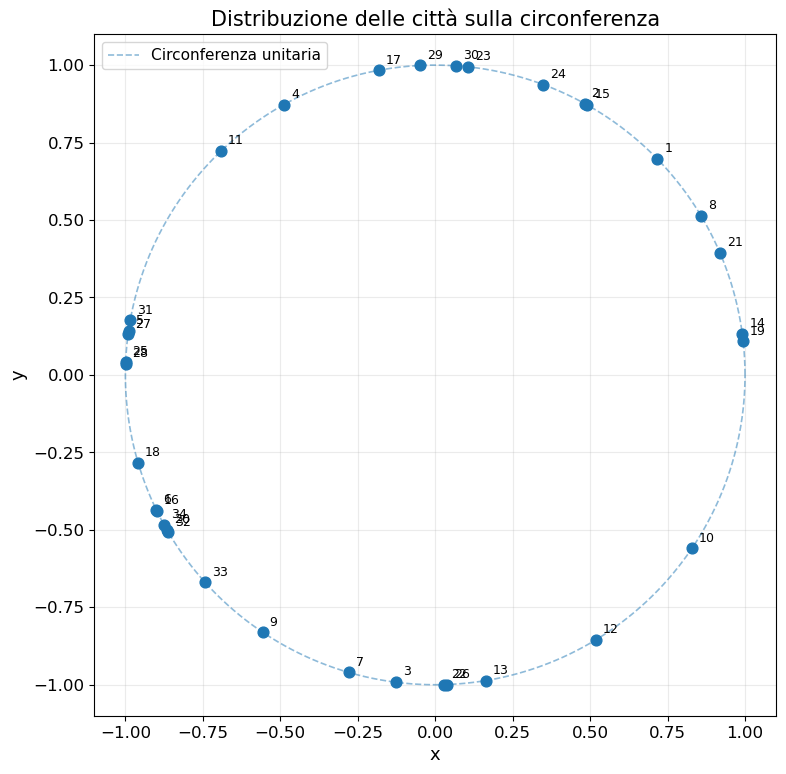

In [8]:
x_circle = circle_cities[:, 1]
y_circle = circle_cities[:, 2]
labels_circle = circle_cities[:, 0].astype(int)

fig, ax = plt.subplots(figsize=(8, 8))

# Circonferenza unitaria di riferimento
theta = np.linspace(0, 2*np.pi, 500)
ax.plot(np.cos(theta), np.sin(theta), linestyle="--",
        linewidth=1.2, alpha=0.5, label="Circonferenza unitaria")

# Posizione delle città
ax.scatter(x_circle, y_circle, s=60, zorder=3)

# Numerazione delle città
for city, x, y in zip(labels_circle, x_circle, y_circle):
    ax.annotate(str(city), (x, y), xytext=(5, 5),
                textcoords="offset points", fontsize=9)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Distribuzione delle città sulla circonferenza")
ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

### Convergenza del Genetic Algorithm

L'evoluzione di $L_{\mathrm{best}}$ viene confrontata con la media della funzione costo sulla migliore metà della popolazione. Una diminuzione delle due quantità indica il progressivo miglioramento dei percorsi presenti nella popolazione.

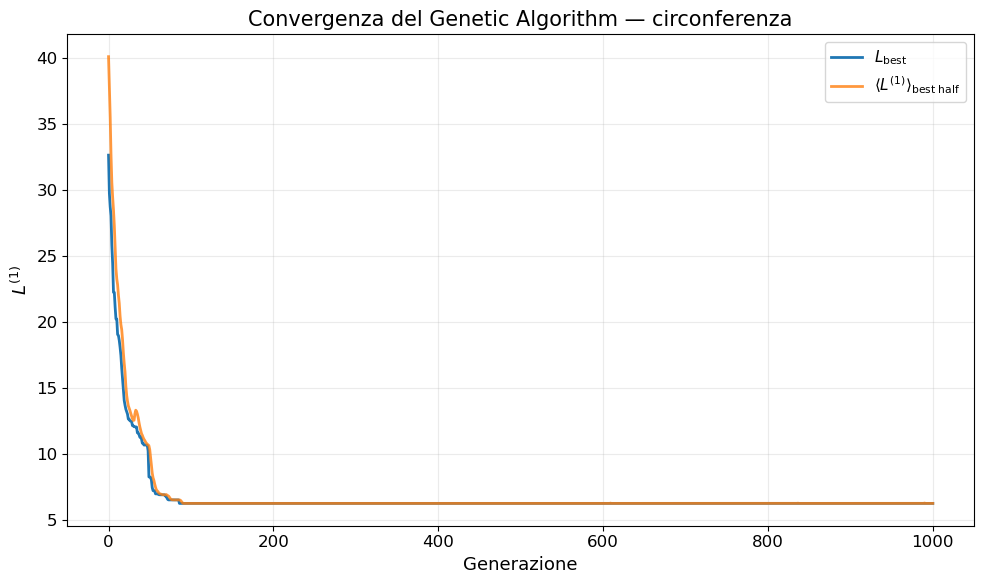

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(gen_circle, best_circle, label=r"$L_{\mathrm{best}}$")
ax.plot(gen_circle, mean_circle,
        label=r"$\langle L^{(1)} \rangle_{\mathrm{best\ half}}$",
        alpha=0.8)

ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L^{(1)}$")
ax.set_title("Convergenza del Genetic Algorithm — circonferenza")
ax.legend()

plt.tight_layout()
plt.show()

La diminuzione della funzione costo è concentrata principalmente nelle prime generazioni. Successivamente viene raggiunto un lungo plateau, indicativo della convergenza della popolazione verso la soluzione finale.

Per rendere più evidente la fase iniziale dell'evoluzione viene quindi considerato uno zoom della regione precedente al plateau.

Miglior lunghezza trovata = 6.243056282025
Prima generazione corrispondente al minimo finale = 86


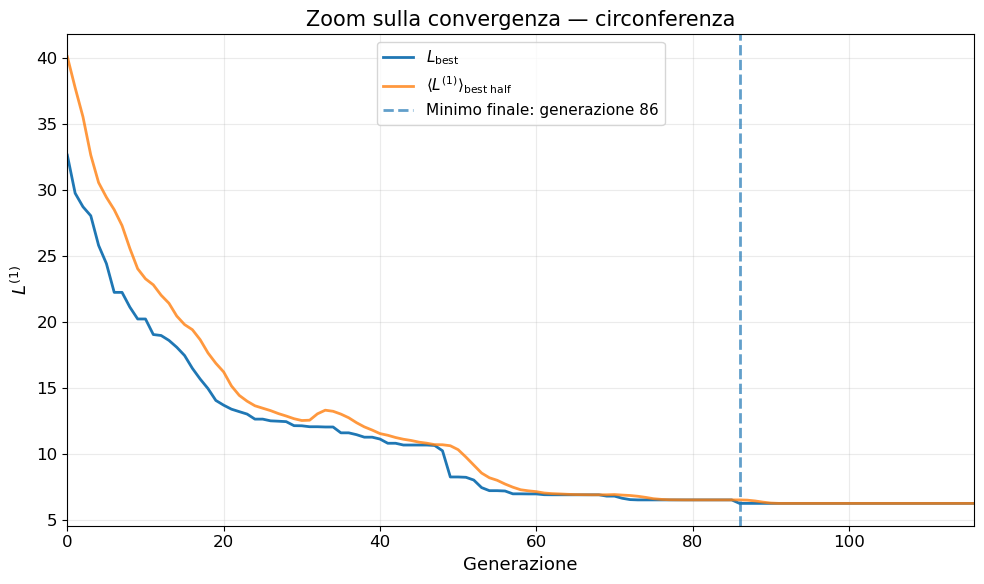

In [11]:
# Valore minimo finale
Lmin_circle = np.min(best_circle)

# Prima generazione in cui viene raggiunto il minimo
first_best_circle = np.where(np.isclose(best_circle, Lmin_circle))[0][0]

print("Miglior lunghezza trovata =", Lmin_circle)
print("Prima generazione corrispondente al minimo finale =", first_best_circle)
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(gen_circle, best_circle, label=r"$L_{\mathrm{best}}$")
ax.plot(gen_circle, mean_circle,
        label=r"$\langle L^{(1)} \rangle_{\mathrm{best\ half}}$",
        alpha=0.8)

ax.axvline(first_best_circle, linestyle="--", alpha=0.7,
           label=f"Minimo finale: generazione {first_best_circle}")

ax.set_xlim(0, first_best_circle + 30)
ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L^{(1)}$")
ax.set_title("Zoom sulla convergenza — circonferenza")
ax.legend()

plt.tight_layout()
plt.show()

### Miglior percorso

Il miglior percorso ottenuto viene rappresentato nel piano cartesiano. Nel caso di punti appartenenti alla circonferenza, il percorso ottimo deve seguire l'ordinamento delle città lungo il bordo, in senso orario oppure antiorario.

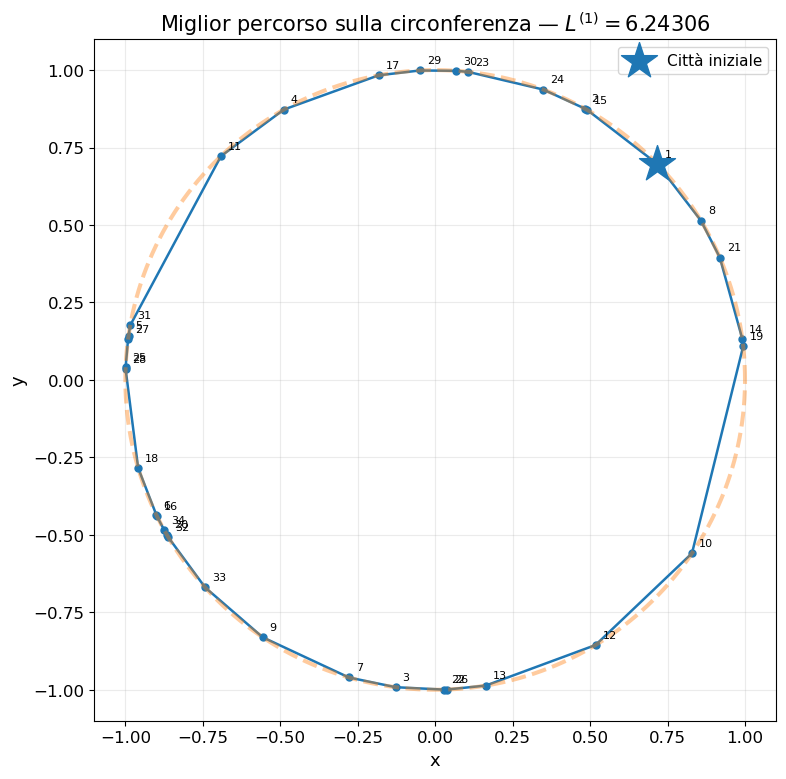

In [41]:
x_path_circle = circle_path[:, 2]
y_path_circle = circle_path[:, 3]
city_path_circle = circle_path[:, 1].astype(int)

fig, ax = plt.subplots(figsize=(8, 8))

# Percorso ottimizzato
ax.plot(x_path_circle, y_path_circle, marker="o",
        markersize=5, linewidth=1.8)
 # Circonferenza di riferimento
ax.plot(
        np.cos(theta),
        np.sin(theta),
        linestyle="--",
        linewidth=2.9,
        alpha=0.4
    )
# Città iniziale
ax.scatter(x_path_circle[0], y_path_circle[0],
           s=740, marker="*", zorder=5, label="Città iniziale")

# Numerazione delle città
for city, x, y in zip(city_path_circle[:-1],
                      x_path_circle[:-1], y_path_circle[:-1]):
    ax.annotate(str(city), (x, y), xytext=(5, 5),
                textcoords="offset points", fontsize=8)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(
    rf"Miglior percorso sulla circonferenza — $L^{{(1)}}={best_circle[-1]:.5f}$"
)
ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

### Verifica della soluzione

Per i punti appartenenti alla circonferenza il percorso ottimo può essere ricavato indipendentemente ordinando le città secondo l'angolo polare $\theta_i=\operatorname{atan2}(y_i,x_i)$.

La lunghezza del percorso ottenuto mediante ordinamento angolare può quindi essere confrontata con quella prodotta dal Genetic Algorithm.

In [17]:
# Angolo polare di ciascuna città
angles = np.arctan2(y_circle, x_circle)

# Ordinamento secondo l'angolo
angular_order = np.argsort(angles)
x_ordered = x_circle[angular_order]
y_ordered = y_circle[angular_order]

# Chiusura del percorso
x_ordered = np.append(x_ordered, x_ordered[0])
y_ordered = np.append(y_ordered, y_ordered[0])

# Calcolo della lunghezza totale
dx = np.diff(x_ordered)
dy = np.diff(y_ordered)
L_circle_exact = np.sum(np.sqrt(dx**2 + dy**2))

print("Risultato del Genetic Algorithm =", best_circle[-1])
print("Percorso ordinato angolarmente =", L_circle_exact)
print("Differenza                     =", abs(best_circle[-1] - L_circle_exact))

Risultato del Genetic Algorithm = 6.243056282025
Percorso ordinato angolarmente = 6.243056282024512
Differenza                     = 4.876099524153688e-13


Il valore prodotto dal Genetic Algorithm coincide, entro la precisione numerica, con quello ottenuto mediante ordinamento angolare. Il Genetic Algorithm ha quindi raggiunto il minimo globale per la configurazione sulla circonferenza.

Il valore ottenuto è leggermente inferiore a $2\pi$ poiché la funzione costo contiene le distanze rettilinee tra città consecutive, cioè le corde della circonferenza, e non gli archi.

## Città distribuite nel quadrato

Nel secondo caso le coordinate delle $34$ città sono estratte uniformemente all'interno del quadrato unitario, secondo $x_i \sim U(0,1)$ e $y_i \sim U(0,1)$.

In questa configurazione il percorso ottimo non è noto a priori e deve essere determinato attraverso l'evoluzione della popolazione.

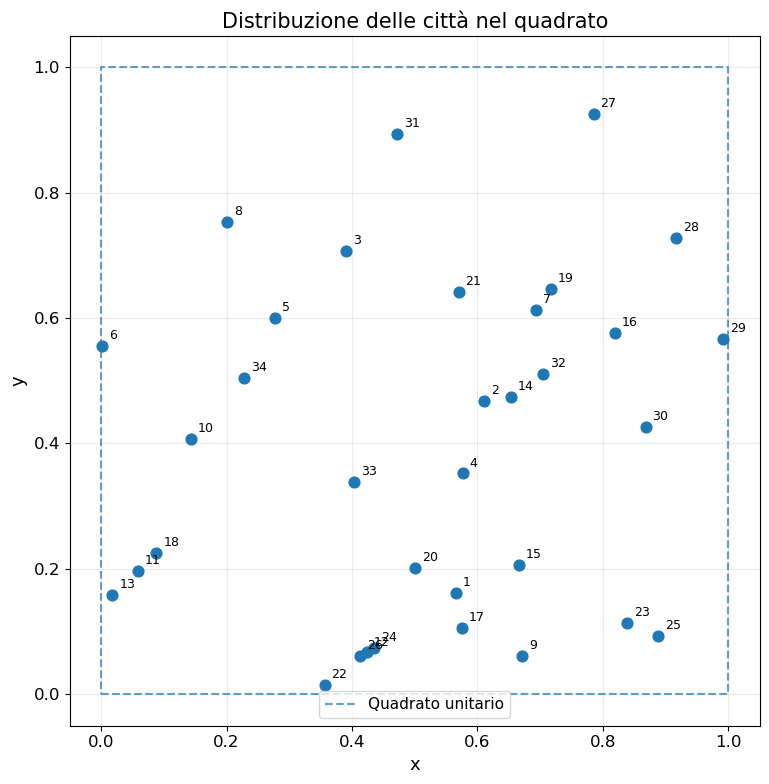

In [25]:
x_square = square_cities[:, 1]
y_square = square_cities[:, 2]
labels_square = square_cities[:, 0].astype(int)

fig, ax = plt.subplots(figsize=(8, 8))

# Punti delle città
ax.scatter(x_square, y_square, s=60, zorder=3)

# Numerazione delle città
for city, x, y in zip(labels_square, x_square, y_square):
    ax.annotate(
        str(city),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# Bordo del quadrato unitario
square_x = [0, 1, 1, 0, 0]
square_y = [0, 0, 1, 1, 0]

ax.plot(
    square_x,
    square_y,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Quadrato unitario"
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Distribuzione delle città nel quadrato")

ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

### Convergenza del Genetic Algorithm

Anche per la configurazione nel quadrato vengono considerate l'evoluzione del miglior individuo e la media della migliore metà della popolazione. La presenza di plateau corrisponde a intervalli di generazioni nei quali non viene individuato un percorso migliore di quello già presente.

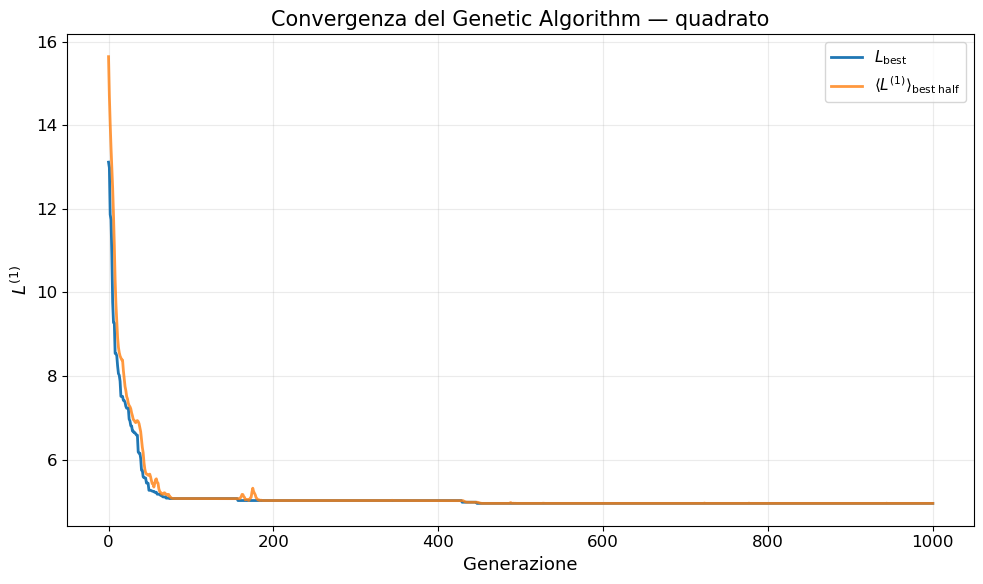

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(gen_square, best_square, label=r"$L_{\mathrm{best}}$")
ax.plot(gen_square, mean_square,
        label=r"$\langle L^{(1)} \rangle_{\mathrm{best\ half}}$",
        alpha=0.8)

ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L^{(1)}$")
ax.set_title("Convergenza del Genetic Algorithm — quadrato")
ax.legend()

plt.tight_layout()
plt.show()

In [20]:
# Valore minimo finale
Lmin_square = np.min(best_square)

# Prima generazione in cui viene raggiunto il minimo
first_best_square = np.where(np.isclose(best_square, Lmin_square))[0][0]

print("Miglior lunghezza trovata =", Lmin_square)
print("Prima generazione corrispondente al minimo finale =", first_best_square)

Miglior lunghezza trovata = 4.951528097142
Prima generazione corrispondente al minimo finale = 447


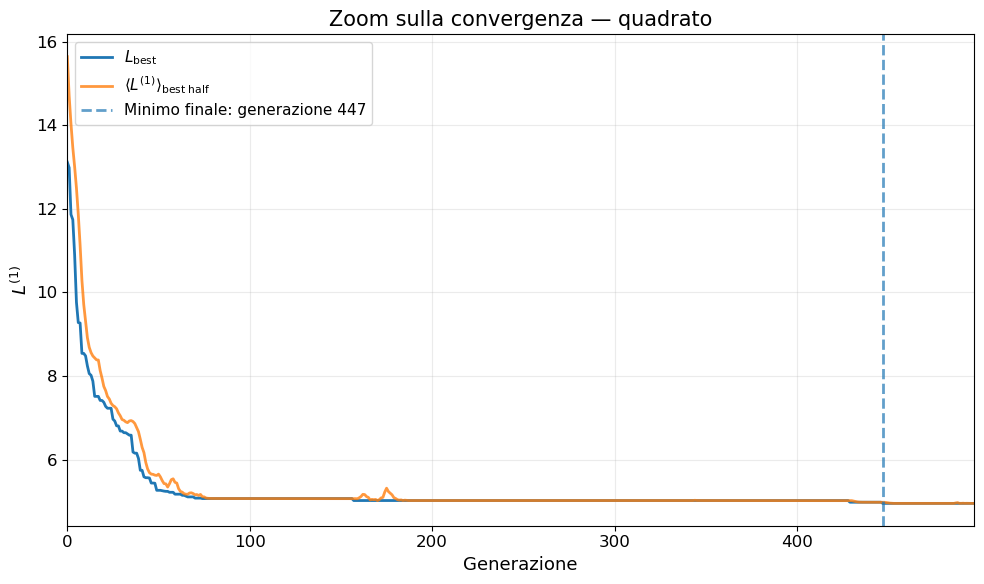

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(gen_square, best_square, label=r"$L_{\mathrm{best}}$")
ax.plot(gen_square, mean_square,
        label=r"$\langle L^{(1)} \rangle_{\mathrm{best\ half}}$",
        alpha=0.8)

ax.axvline(first_best_square, linestyle="--", alpha=0.7,
           label=f"Minimo finale: generazione {first_best_square}")

ax.set_xlim(0, first_best_square + 50)
ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L^{(1)}$")
ax.set_title("Zoom sulla convergenza — quadrato")
ax.legend()

plt.tight_layout()
plt.show()

Nel caso del quadrato la convergenza avviene attraverso una successione di miglioramenti intervallati da plateau. Durante un plateau il miglior individuo rimane invariato, mentre crossover e mutazioni continuano a generare nuove configurazioni.

La comparsa di un individuo caratterizzato da una funzione costo inferiore determina un nuovo abbassamento di $L_{\mathrm{best}}$.

### Miglior percorso nel quadrato

Il miglior percorso ottenuto viene rappresentato nel piano cartesiano. Nel TSP euclideo un percorso ottimo non può presentare intersezioni tra segmenti non consecutivi, poiché un incrocio può essere eliminato mediante una riconnessione che produce un percorso più corto.

L'assenza di incroci rappresenta quindi una condizione necessaria, anche se non sufficiente, per l'ottimalità del percorso.

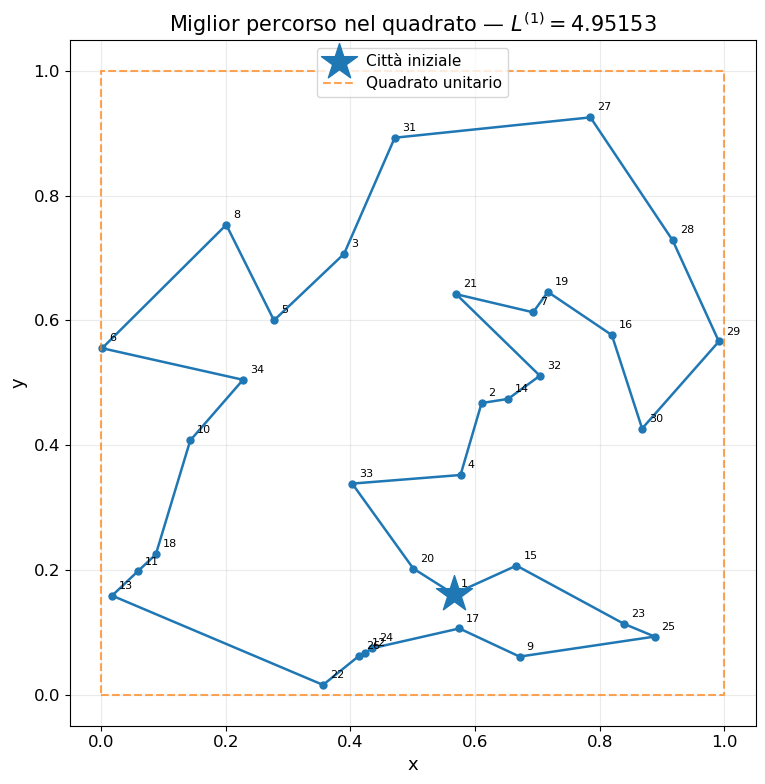

In [38]:
x_path_square = square_path[:, 2]
y_path_square = square_path[:, 3]
city_path_square = square_path[:, 1].astype(int)

fig, ax = plt.subplots(figsize=(8, 8))

# Miglior percorso
ax.plot(
    x_path_square,
    y_path_square,
    marker="o",
    markersize=5,
    linewidth=1.8
)

# Città iniziale
ax.scatter(
    x_path_square[0],
    y_path_square[0],
    s=740,
    marker="*",
    zorder=5,
    label="Città iniziale"
)

# Numerazione delle città
for city, x, y in zip(
    city_path_square[:-1],
    x_path_square[:-1],
    y_path_square[:-1]
):
    ax.annotate(
        str(city),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Bordo del quadrato unitario
square_x = [0, 1, 1, 0, 0]
square_y = [0, 0, 1, 1, 0]

ax.plot(
    square_x,
    square_y,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Quadrato unitario"
)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(
    rf"Miglior percorso nel quadrato — $L^{{(1)}}={best_square[-1]:.5f}$"
)

ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

## Confronto della convergenza

Poiché le due configurazioni presentano valori iniziali differenti della funzione costo, viene utilizzata una normalizzazione rispetto al valore iniziale:

$\widetilde{L}_{\mathrm{best}}(t)=\frac{L_{\mathrm{best}}(t)}{L_{\mathrm{best}}(0)}$

In questo modo entrambe le curve assumono valore $1$ alla generazione iniziale e può essere confrontata direttamente la velocità relativa di convergenza.

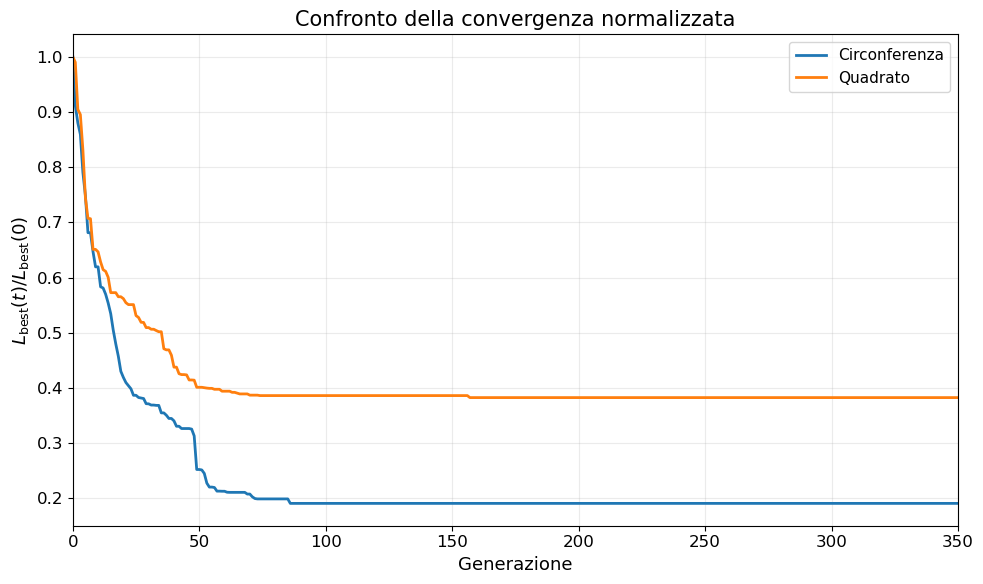

In [24]:
# Normalizzazione rispetto al valore iniziale
best_circle_norm = best_circle / best_circle[0]
best_square_norm = best_square / best_square[0]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(gen_circle, best_circle_norm, label="Circonferenza")
ax.plot(gen_square, best_square_norm, label="Quadrato")

ax.set_xlim(0, 350)
ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L_{\mathrm{best}}(t)/L_{\mathrm{best}}(0)$")
ax.set_title("Confronto della convergenza normalizzata")
ax.legend()

plt.tight_layout()
plt.show()

Il confronto normalizzato mostra che la convergenza risulta più rapida nel caso della circonferenza. In tale configurazione la struttura geometrica della soluzione ottima è più semplice, poiché il percorso minimo coincide con l'ordinamento delle città lungo la circonferenza. Nel caso del quadrato, invece, la soluzione ottima non è nota a priori e la convergenza risulta meno rapida.

## Evoluzione geometrica del miglior percorso

Oltre all'andamento della funzione costo, è utile osservare direttamente come cambia il miglior percorso presente nella popolazione durante l'evoluzione del Genetic Algorithm.

Sono stati quindi salvati alcuni snapshot del miglior individuo alle generazioni $0$, $10$, $20$, $50$, $100$, $200$, $500$ e $1000$.

Per ciascuna generazione viene rappresentato il percorso corrispondente e viene riportato il relativo valore di $L^{(1)}$. In questo modo è possibile osservare direttamente la progressiva riorganizzazione geometrica del cromosoma.

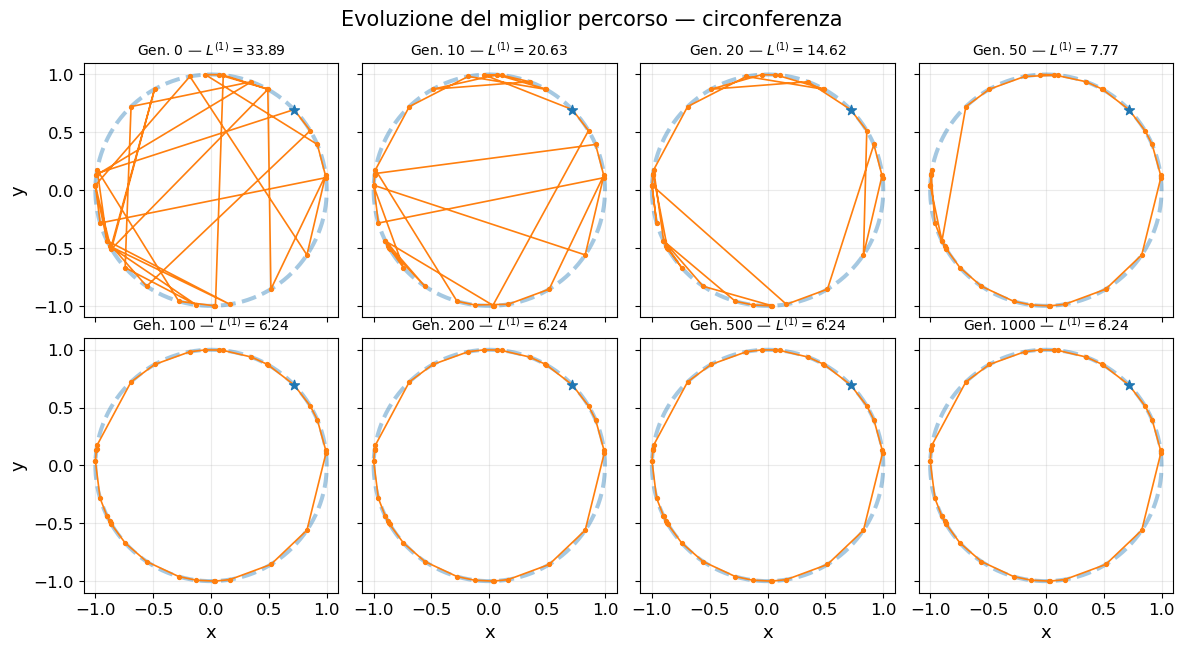

In [39]:
# Generazioni per le quali sono stati salvati i migliori percorsi
snapshot_generations = [0, 10, 20, 50, 100, 200, 500, 1000]

# Dizionari contenenti i percorsi alle diverse generazioni
circle_snapshots = {}
square_snapshots = {}

for gen in snapshot_generations:
    circle_snapshots[gen] = np.loadtxt(
        f"Esercizio_09.1/circle_best_path_gen_{gen}.txt"
    )

    square_snapshots[gen] = np.loadtxt(
        f"Esercizio_09.1/square_best_path_gen_{gen}.txt"
    )


def path_length_from_snapshot(path_data):
    """
    Calcola la lunghezza totale del percorso a partire
    dalle coordinate contenute in un file snapshot.
    
    L'ultima riga contiene già la ripetizione
    della città iniziale.
    """

    x = path_data[:, 2]
    y = path_data[:, 3]

    dx = np.diff(x)
    dy = np.diff(y)

    return np.sum(np.sqrt(dx**2 + dy**2))

fig, axes = plt.subplots(
    2, 4,
    figsize=(12, 6.5),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Circonferenza unitaria di riferimento
theta = np.linspace(0, 2*np.pi, 500)

for ax, gen in zip(axes, snapshot_generations):

    path_data = circle_snapshots[gen]

    x = path_data[:, 2]
    y = path_data[:, 3]

    # Lunghezza del percorso
    L = path_length_from_snapshot(path_data)

    # Circonferenza di riferimento
    ax.plot(
        np.cos(theta),
        np.sin(theta),
        linestyle="--",
        linewidth=2.9,
        alpha=0.4
    )

    # Miglior percorso della generazione
    ax.plot(
        x,
        y,
        marker="o",
        markersize=2.8,
        linewidth=1.2
    )

    # Città iniziale
    ax.scatter(
        x[0],
        y[0],
        marker="*",
        s=55,
        zorder=5
    )

    ax.set_title(
        rf"Gen. {gen} — $L^{{(1)}}={L:.2f}$",
        fontsize=10
    )

    ax.set_aspect("equal")
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)

# Etichette solo ai bordi della figura
for ax in axes[4:]:
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
axes[4].set_ylabel("y")

fig.suptitle(
    "Evoluzione del miglior percorso — circonferenza",
    fontsize=15
)

plt.tight_layout()
plt.show()

La sequenza mostra direttamente l'effetto dell'evoluzione genetica sul miglior individuo. Nelle prime generazioni il percorso contiene numerosi collegamenti lunghi tra regioni lontane della circonferenza, con una conseguente elevata funzione costo.

Con il procedere delle generazioni tali collegamenti vengono progressivamente eliminati e il percorso tende a seguire l'ordinamento delle città lungo il bordo. La diminuzione di $L^{(1)}$ è quindi associata a una chiara regolarizzazione geometrica del cromosoma.

Nelle generazioni finali il percorso coincide con l'ordinamento angolare delle città, corrispondente al minimo globale per questa configurazione.

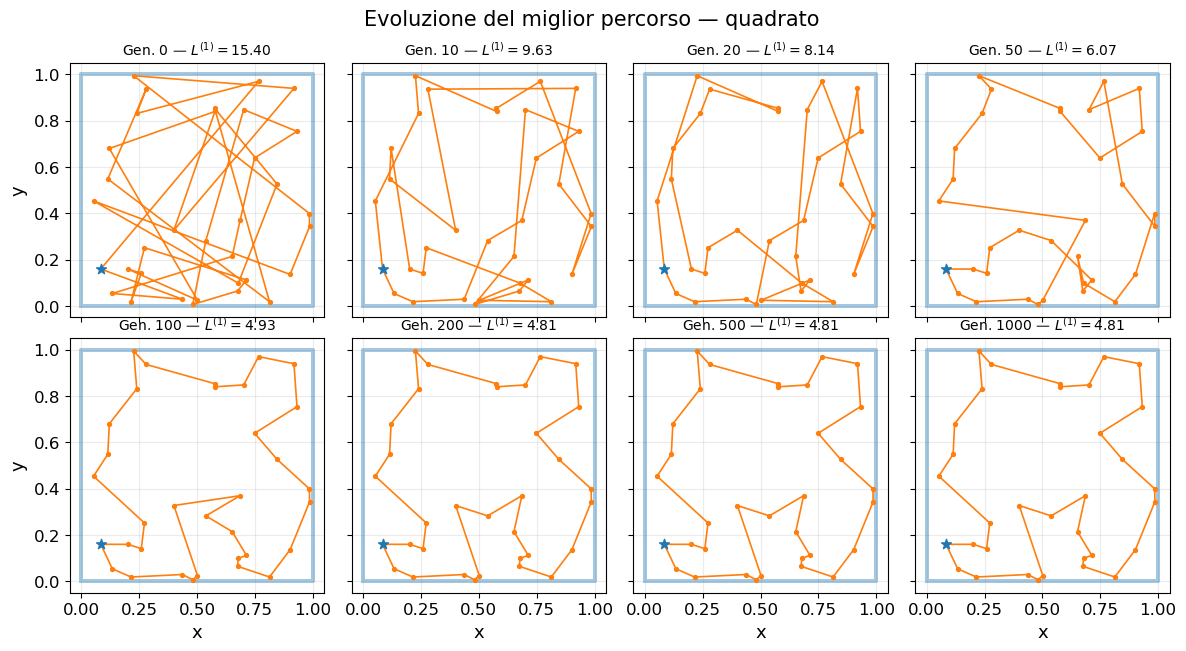

In [36]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(12, 6.5),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Coordinate del bordo del quadrato unitario
square_x = [0, 1, 1, 0, 0]
square_y = [0, 0, 1, 1, 0]

for ax, gen in zip(axes, snapshot_generations):

    path_data = square_snapshots[gen]

    x = path_data[:, 2]
    y = path_data[:, 3]

    # Lunghezza del percorso
    L = path_length_from_snapshot(path_data)

    # Bordo del quadrato
    ax.plot(
        square_x,
        square_y,
        linestyle="-",
        linewidth=2.9,
        alpha=0.4
    )

    # Miglior percorso della generazione
    ax.plot(
        x,
        y,
        marker="o",
        markersize=2.8,
        linewidth=1.2
    )

    # Città iniziale
    ax.scatter(
        x[0],
        y[0],
        marker="*",
        s=55,
        zorder=5
    )

    ax.set_title(
        rf"Gen. {gen} — $L^{{(1)}}={L:.2f}$",
        fontsize=10
    )

    ax.set_aspect("equal")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)

# Etichette solo ai bordi della figura
for ax in axes[4:]:
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
axes[4].set_ylabel("y")

fig.suptitle(
    "Evoluzione del miglior percorso — quadrato",
    fontsize=15
)

plt.tight_layout()
plt.show()

Anche nel quadrato la struttura del miglior percorso cambia sensibilmente durante le prime generazioni. Il candidato iniziale presenta numerosi collegamenti lunghi tra città distanti, mentre l'evoluzione tende progressivamente a favorire collegamenti tra punti geometricamente più vicini.

Con il procedere delle generazioni il percorso diventa quindi più regolare e compatto. La riduzione del numero di collegamenti inefficienti e l'assenza di incroci nelle configurazioni finali sono coerenti con la progressiva diminuzione di $L^{(1)}$ osservata nei grafici di convergenza.

### Confronto con e senza elitismo

Per valutare l'effetto dell'elitismo viene confrontato l'andamento di $L_{\mathrm{best}}$ ottenuto mantenendo il miglior individuo nella generazione successiva con quello ottenuto senza elitismo.

In presenza di elitismo il miglior valore trovato non può essere perso e quindi $L_{\mathrm{best}}$ può solamente diminuire o rimanere costante. Senza elitismo, invece, il miglior individuo può non essere trasmesso alla generazione successiva e sono quindi possibili aumenti temporanei della funzione costo.

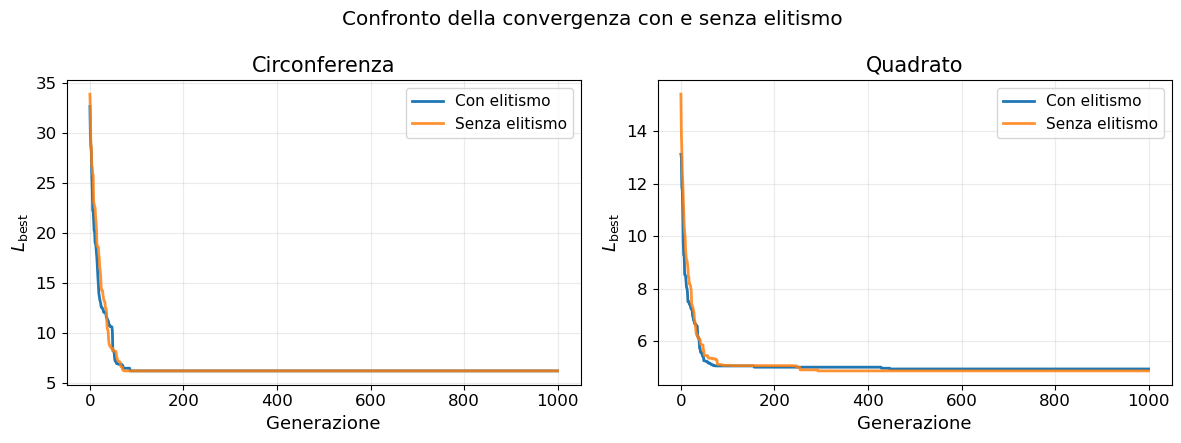

In [43]:
# Caricamento delle simulazioni senza elitismo
circle_no_elite = np.loadtxt("Esercizio_09.1/circle_no_elite_convergence.txt")
square_no_elite = np.loadtxt("Esercizio_09.1/square_no_elite_convergence.txt")

gen_circle_no_elite = circle_no_elite[:, 0]
best_circle_no_elite = circle_no_elite[:, 1]

gen_square_no_elite = square_no_elite[:, 0]
best_square_no_elite = square_no_elite[:, 1]


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ============================================================
# Circonferenza
# ============================================================

axes[0].plot(
    gen_circle,
    best_circle,
    label="Con elitismo"
)

axes[0].plot(
    gen_circle_no_elite,
    best_circle_no_elite,
    label="Senza elitismo",
    alpha=0.85
)

axes[0].set_xlabel("Generazione")
axes[0].set_ylabel(r"$L_{\mathrm{best}}$")
axes[0].set_title("Circonferenza")
axes[0].legend()


# ============================================================
# Quadrato
# ============================================================

axes[1].plot(
    gen_square,
    best_square,
    label="Con elitismo"
)

axes[1].plot(
    gen_square_no_elite,
    best_square_no_elite,
    label="Senza elitismo",
    alpha=0.85
)

axes[1].set_xlabel("Generazione")
axes[1].set_ylabel(r"$L_{\mathrm{best}}$")
axes[1].set_title("Quadrato")
axes[1].legend()


fig.suptitle("Confronto della convergenza con e senza elitismo")

plt.tight_layout()
plt.show()

Il confronto mostra che l'introduzione dell'elitismo non modifica in modo sostanziale la velocità di convergenza nelle simulazioni considerate. Nel caso della circonferenza le due curve risultano quasi sovrapposte e raggiungono lo stesso minimo finale.

Nel caso del quadrato sono presenti differenze leggermente maggiori e, nella singola simulazione effettuata, l'algoritmo senza elitismo raggiunge un valore finale di $L_{\mathrm{best}}$ leggermente inferiore. Questo risultato non implica tuttavia una superiorità generale della configurazione senza elitismo, poiché il Genetic Algorithm è un algoritmo stocastico e il confronto tra le due strategie richiederebbe diverse simulazioni indipendenti.

In assenza di elitismo il miglior individuo può teoricamente essere perso da una generazione alla successiva, mentre con elitismo viene sempre conservato. Tuttavia, quando la popolazione è già concentrata attorno a configurazioni molto simili, la perdita del singolo miglior cromosoma può avere un effetto limitato sull'andamento complessivo.

## Conclusioni

Il Genetic Algorithm produce in entrambe le configurazioni una rapida diminuzione della funzione costo rispetto alla popolazione casuale iniziale.

Per le città sulla circonferenza viene ottenuto $L_{\mathrm{best}} \simeq 6.24306$. Il confronto con la soluzione costruita mediante ordinamento angolare conferma il raggiungimento del minimo globale.

Per le città distribuite nel quadrato viene ottenuto $L_{\mathrm{best}} \simeq 5.35103$. In questo caso la convergenza avviene attraverso diversi plateau, separati dalla comparsa di nuovi cromosomi caratterizzati da una funzione costo inferiore.

La progressiva convergenza di $\langle L^{(1)} \rangle_{\mathrm{best\ half}}$ verso $L_{\mathrm{best}}$ indica inoltre una riduzione della diversità della popolazione e una crescente concentrazione degli individui attorno alle configurazioni migliori.

L'utilizzo combinato di selezione, crossover e mutazione permette quindi di esplorare lo spazio delle possibili permutazioni e, contemporaneamente, di favorire la propagazione delle configurazioni caratterizzate da percorsi più corti.

## Extra — Traveling Salesman Problem sulla superficie di una sfera

Come estensione del problema, il Genetic Algorithm viene applicato a $N=100$ città distribuite uniformemente sulla superficie di una sfera unitaria.

In questo caso la distanza tra due città non viene calcolata mediante il segmento rettilineo nello spazio tridimensionale, ma tramite la distanza geodetica lungo la superficie della sfera:

$d_{ij} = \arccos(\mathbf{r}_i \cdot \mathbf{r}_j)$

dove $\mathbf{r}_i$ e $\mathbf{r}_j$ sono i vettori posizione delle due città sulla sfera unitaria.

La funzione costo diventa quindi:

$L_{\mathrm{sph}} = \sum_{i=1}^{N} d_{i,i+1}$

con ritorno alla città iniziale.

In [76]:
# Caricamento dei dati relativi alla sfera
sphere_cities = np.loadtxt("Esercizio_09_extra_sphere/sphere_cities.txt")
sphere_conv = np.loadtxt("Esercizio_09_extra_sphere/sphere_convergence.txt")
sphere_path = np.loadtxt("Esercizio_09_extra_sphere/sphere_best_path.txt")

# Dati di convergenza
gen_sphere = sphere_conv[:, 0]
best_sphere = sphere_conv[:, 1]
mean_sphere = sphere_conv[:, 2]

print("Numero di città:", len(sphere_cities))
print("L_best finale =", best_sphere[-1])


def great_circle_arc(p1, p2, n_points=30):
    """
    Costruisce l'arco geodetico sulla sfera unitaria
    tra due punti p1 e p2.
    """

    p1 = np.asarray(p1, dtype=float)
    p2 = np.asarray(p2, dtype=float)

    # Prodotto scalare e angolo tra i due vettori
    dot = np.clip(np.dot(p1, p2), -1.0, 1.0)
    omega = np.arccos(dot)

    # Caso di punti molto vicini
    if omega < 1e-10:
        return np.tile(p1, (n_points, 1))

    t = np.linspace(0, 1, n_points)

    # Interpolazione sferica
    arc = (
        np.sin((1 - t) * omega)[:, None] * p1
        + np.sin(t * omega)[:, None] * p2
    ) / np.sin(omega)

    return arc

def plot_geodesic_visible_hidden(
    ax,
    p1,
    p2,
    elev=25,
    azim=-60,
    n_points=50,
    linewidth=1.6
):
    """
    Disegna l'arco geodetico tra p1 e p2.

    - linea continua: parte visibile della sfera
    - linea tratteggiata: parte dietro la sfera
    """

    # Arco geodetico
    arc = great_circle_arc(p1, p2, n_points=n_points)

    # Direzione dalla sfera verso l'osservatore
    elev_rad = np.radians(elev)
    azim_rad = np.radians(azim)

    view_direction = np.array([
        np.cos(elev_rad) * np.cos(azim_rad),
        np.cos(elev_rad) * np.sin(azim_rad),
        np.sin(elev_rad)
    ])

    # Ogni piccolo tratto viene classificato
    # usando il suo punto medio
    for i in range(len(arc) - 1):

        midpoint = (arc[i] + arc[i + 1]) / 2

        # Prodotto scalare > 0 -> emisfero rivolto verso l'osservatore
        visible = np.dot(midpoint, view_direction) >= 0

        if visible:
            ax.plot(
                arc[i:i+2, 0],
                arc[i:i+2, 1],
                arc[i:i+2, 2],
                color="C0",
                linestyle="-",
                linewidth=linewidth
            )

        else:
            ax.plot(
                arc[i:i+2, 0],
                arc[i:i+2, 1],
                arc[i:i+2, 2],
                color="C0",
                linestyle="--",
                linewidth=linewidth,
                alpha=0.55
            )

Numero di città: 100
L_best finale = 28.00676259311


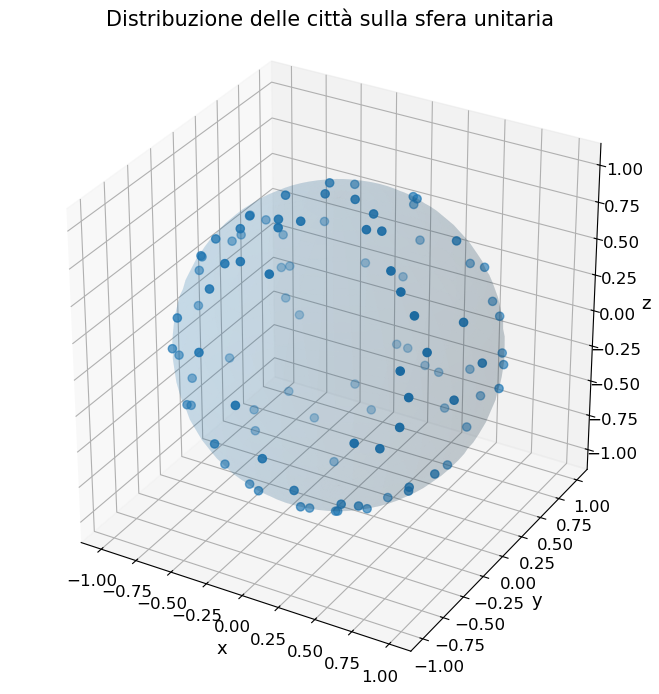

In [77]:
from mpl_toolkits.mplot3d import Axes3D

x_sphere = sphere_cities[:, 1]
y_sphere = sphere_cities[:, 2]
z_sphere = sphere_cities[:, 3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# Superficie della sfera
u = np.linspace(0, 2*np.pi, 60)
v = np.linspace(0, np.pi, 30)

X = np.outer(np.cos(u), np.sin(v))
Y = np.outer(np.sin(u), np.sin(v))
Z = np.outer(np.ones_like(u), np.cos(v))

ax.plot_surface(
    X, Y, Z,
    alpha=0.12,
    linewidth=0
)

# Città
ax.scatter(
    x_sphere,
    y_sphere,
    z_sphere,
    s=35
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Distribuzione delle città sulla sfera unitaria")

ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

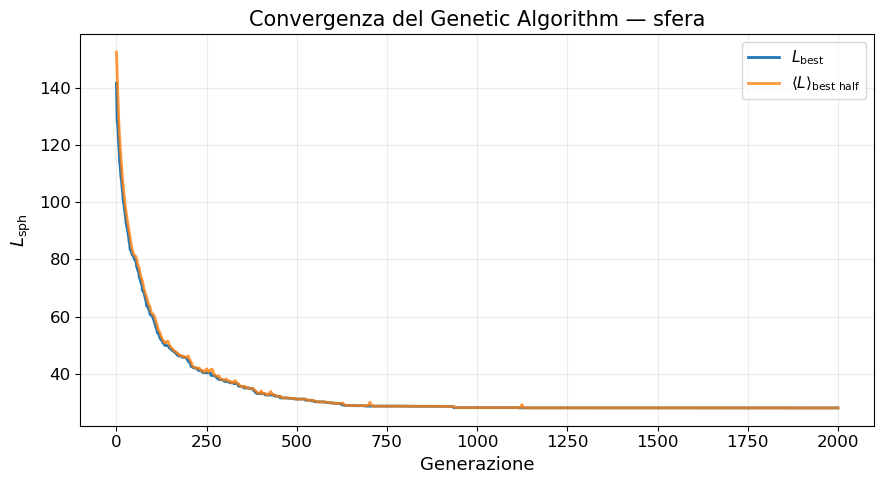

In [78]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    gen_sphere,
    best_sphere,
    label=r"$L_{\mathrm{best}}$"
)

ax.plot(
    gen_sphere,
    mean_sphere,
    label=r"$\langle L \rangle_{\mathrm{best\ half}}$",
    alpha=0.8
)

ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L_{\mathrm{sph}}$")
ax.set_title("Convergenza del Genetic Algorithm — sfera")

ax.legend()

plt.tight_layout()
plt.show()

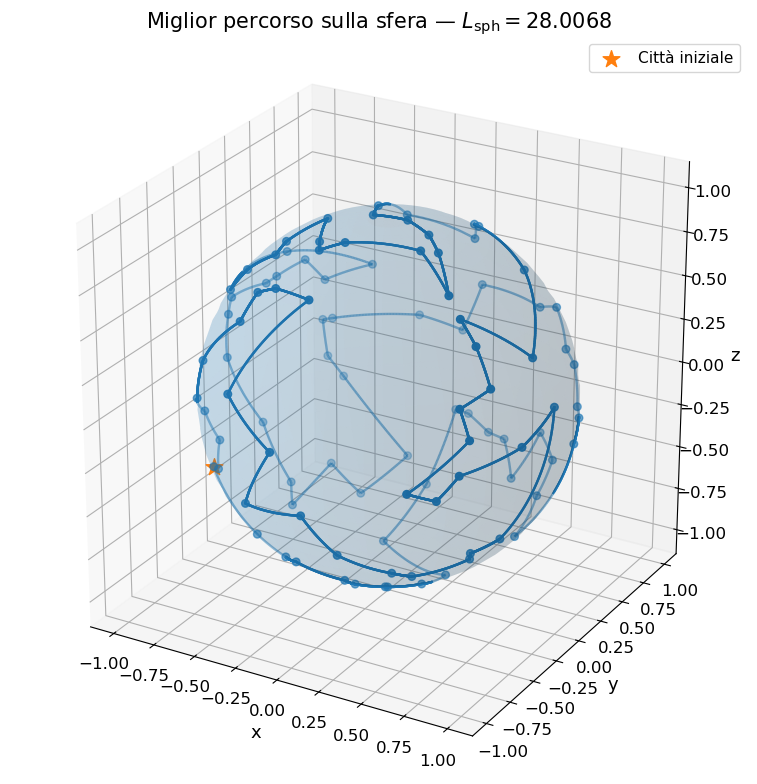

In [79]:
# Coordinate del miglior percorso
points = sphere_path[:, 2:5]

# Punto di vista scelto
elev = 25
azim = -60

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

# Punto di vista
ax.view_init(elev=elev, azim=azim)

# Superficie della sfera
ax.plot_surface(
    X, Y, Z,
    alpha=0.13,
    linewidth=0
)

# Città
ax.scatter(
    points[:-1, 0],
    points[:-1, 1],
    points[:-1, 2],
    s=30,
    zorder=3
)

# Percorso geodetico
for i in range(len(points) - 1):

    plot_geodesic_visible_hidden(
        ax,
        points[i],
        points[i + 1],
        elev=elev,
        azim=azim,
        n_points=60,
        linewidth=1.7
    )

# Città iniziale
ax.scatter(
    points[0, 0],
    points[0, 1],
    points[0, 2],
    marker="*",
    s=160,
    label="Città iniziale"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title(
    rf"Miglior percorso sulla sfera — $L_{{\mathrm{{sph}}}}={best_sphere[-1]:.4f}$"
)

ax.set_box_aspect([1, 1, 1])
ax.legend()

plt.tight_layout()
plt.show()

Il percorso finale segue archi geodetici sulla superficie della sfera e tende a collegare città relativamente vicine, evitando spostamenti inutilmente lunghi tra regioni distanti.

A differenza del caso della circonferenza, non esiste un semplice ordinamento angolare che determini direttamente la soluzione ottima. Il problema sferico costituisce quindi un'estensione più complessa del TSP bidimensionale, pur mantenendo invariata la struttura del Genetic Algorithm.

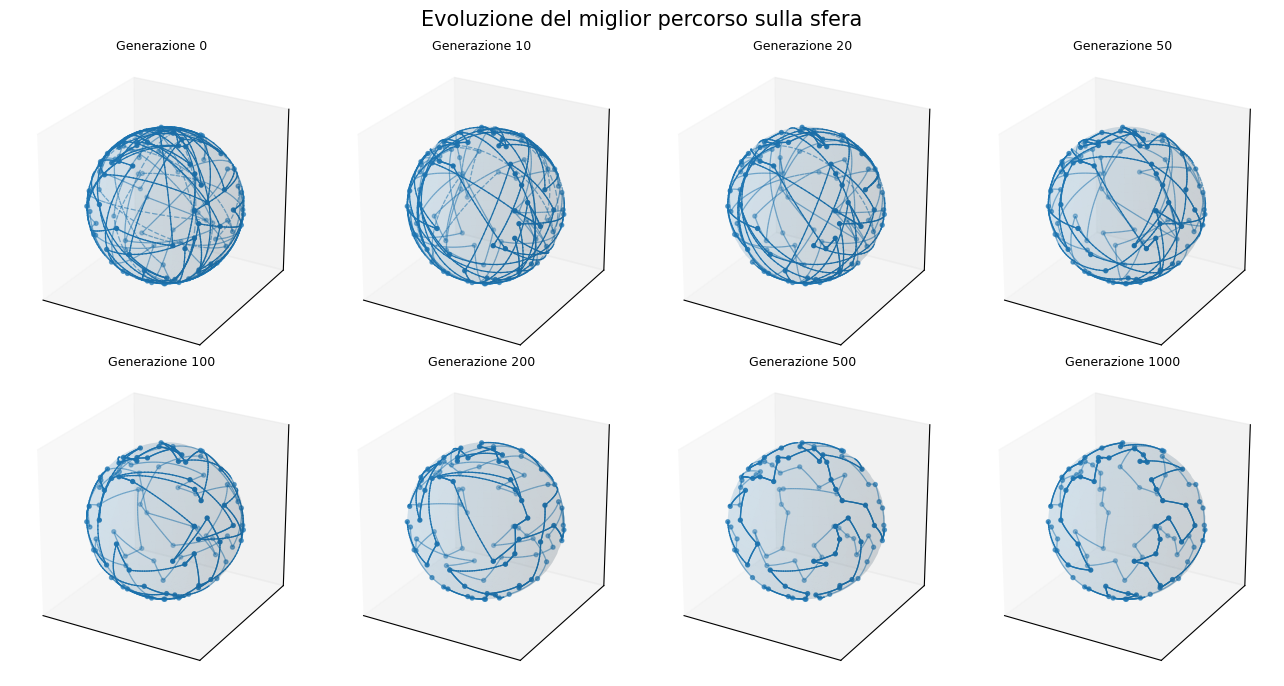

In [71]:
snapshot_generations = [0, 10, 20, 50, 100, 200, 500, 1000]

# Stesso punto di vista per tutti i pannelli
elev = 25
azim = -60

fig = plt.figure(figsize=(13, 7))

for k, gen in enumerate(snapshot_generations):

    ax = fig.add_subplot(
        2, 4, k + 1,
        projection="3d"
    )

    # Stesso punto di vista per tutti i grafici
    ax.view_init(elev=elev, azim=azim)

    data = np.loadtxt(
        f"Esercizio_09_extra_sphere/sphere_best_path_gen_{gen}.txt"
    )

    points_gen = data[:, 2:5]

    # Sfera
    ax.plot_surface(
        X, Y, Z,
        alpha=0.09,
        linewidth=0
    )

    # Città
    ax.scatter(
        points_gen[:-1, 0],
        points_gen[:-1, 1],
        points_gen[:-1, 2],
        s=8
    )

    # Percorso geodetico:
    # continuo davanti, tratteggiato dietro
    for i in range(len(points_gen) - 1):

        plot_geodesic_visible_hidden(
            ax,
            points_gen[i],
            points_gen[i + 1],
            elev=elev,
            azim=azim,
            n_points=25,
            linewidth=0.9
        )

    ax.set_title(
        f"Generazione {gen}",
        fontsize=9
    )

    ax.set_box_aspect([1, 1, 1])

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

fig.suptitle(
    "Evoluzione del miglior percorso sulla sfera",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Extra 2 — Traveling Salesman Problem in un cubo tridimensionale

Come ulteriore estensione, il Genetic Algorithm viene applicato a $N=100$ città distribuite uniformemente all'interno del cubo unitario:

$0 \leq x,y,z < 1$.

La distanza tra due città è la distanza euclidea tridimensionale:

$d_{ij} = \sqrt{(x_i-x_j)^2+(y_i-y_j)^2+(z_i-z_j)^2}$.

La funzione costo mantiene quindi la stessa struttura del problema originale:

$L^{(1)} = \sum_{i=1}^{N} d_{i,i+1}$,

con ritorno alla città iniziale. La struttura del Genetic Algorithm rimane invariata; cambia solamente la geometria dello spazio in cui sono distribuite le città.

In [80]:
# Caricamento dei dati relativi al cubo

cube_cities = np.loadtxt("Esercizio_09_extra_cube/cube_cities.txt")
cube_conv = np.loadtxt("Esercizio_09_extra_cube/cube_convergence.txt")
cube_path = np.loadtxt("Esercizio_09_extra_cube/cube_best_path.txt")

# Dati di convergenza
gen_cube = cube_conv[:, 0]
best_cube = cube_conv[:, 1]
mean_cube = cube_conv[:, 2]

print("Numero di città:", len(cube_cities))
print("L_best finale =", best_cube[-1])

Numero di città: 100
L_best finale = 17.73839923468


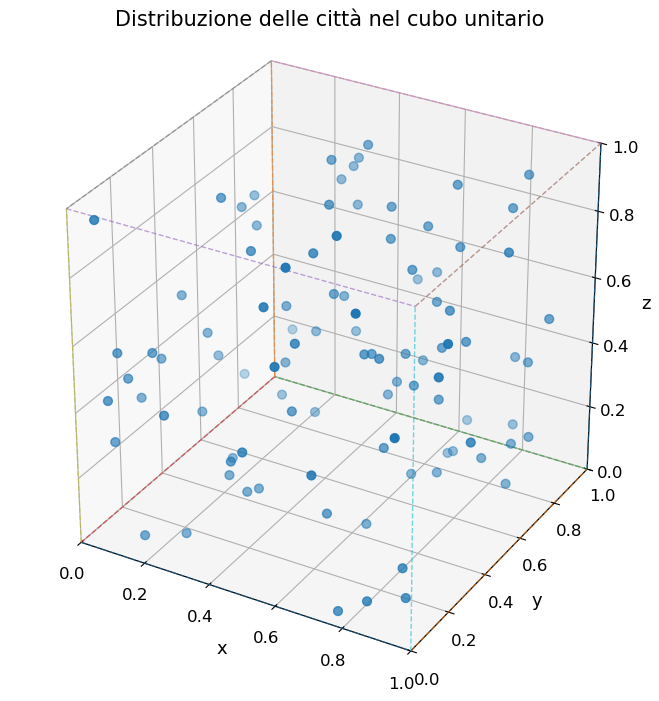

In [81]:
from mpl_toolkits.mplot3d import Axes3D

x_cube = cube_cities[:, 1]
y_cube = cube_cities[:, 2]
z_cube = cube_cities[:, 3]


# Vertici del cubo unitario
cube_vertices = np.array([
    [0, 0, 0],
    [1, 0, 0],
    [1, 1, 0],
    [0, 1, 0],
    [0, 0, 1],
    [1, 0, 1],
    [1, 1, 1],
    [0, 1, 1]
])


# Coppie di vertici che definiscono gli spigoli
cube_edges = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7)
]


fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")


# Spigoli del cubo
for i, j in cube_edges:
    ax.plot(
        [cube_vertices[i, 0], cube_vertices[j, 0]],
        [cube_vertices[i, 1], cube_vertices[j, 1]],
        [cube_vertices[i, 2], cube_vertices[j, 2]],
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )


# Città
ax.scatter(
    x_cube,
    y_cube,
    z_cube,
    s=40
)


ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_title("Distribuzione delle città nel cubo unitario")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)

ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

### Convergenza

Anche nel caso tridimensionale vengono monitorati il miglior valore della funzione costo $L_{\mathrm{best}}$ e il valore medio della migliore metà della popolazione.

La diminuzione delle due quantità indica la progressiva selezione di percorsi caratterizzati da collegamenti tridimensionali complessivamente più brevi.

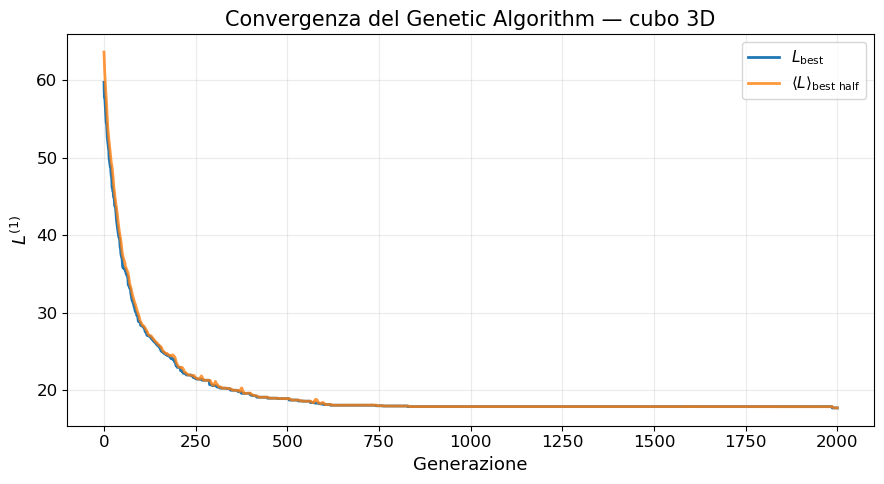

In [82]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    gen_cube,
    best_cube,
    label=r"$L_{\mathrm{best}}$"
)

ax.plot(
    gen_cube,
    mean_cube,
    label=r"$\langle L \rangle_{\mathrm{best\ half}}$",
    alpha=0.8
)

ax.set_xlabel("Generazione")
ax.set_ylabel(r"$L^{(1)}$")
ax.set_title("Convergenza del Genetic Algorithm — cubo 3D")

ax.legend()

plt.tight_layout()
plt.show()

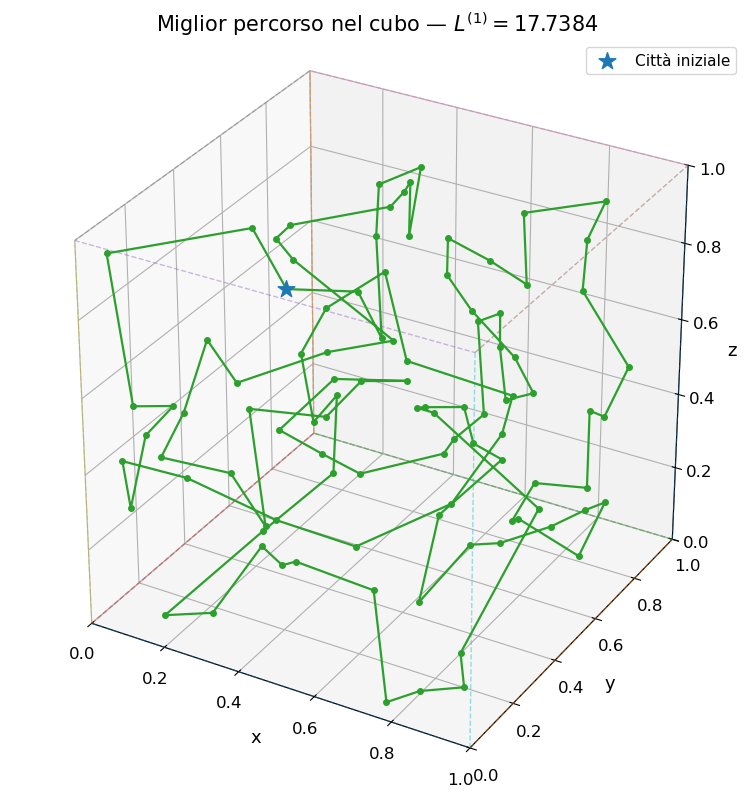

In [83]:
# Coordinate del miglior percorso
points_cube = cube_path[:, 2:5]

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")


# ============================================================
# Cubo unitario
# ============================================================

for i, j in cube_edges:

    ax.plot(
        [cube_vertices[i, 0], cube_vertices[j, 0]],
        [cube_vertices[i, 1], cube_vertices[j, 1]],
        [cube_vertices[i, 2], cube_vertices[j, 2]],
        linestyle="--",
        linewidth=1,
        alpha=0.45
    )


# ============================================================
# Miglior percorso
# ============================================================

ax.plot(
    points_cube[:, 0],
    points_cube[:, 1],
    points_cube[:, 2],
    marker="o",
    markersize=4,
    linewidth=1.6
)


# Città iniziale
ax.scatter(
    points_cube[0, 0],
    points_cube[0, 1],
    points_cube[0, 2],
    marker="*",
    s=160,
    zorder=5,
    label="Città iniziale"
)


ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 1)

ax.set_title(
    rf"Miglior percorso nel cubo — $L^{{(1)}}={best_cube[-1]:.4f}$"
)

ax.set_box_aspect([1, 1, 1])

ax.legend()

plt.tight_layout()
plt.show()

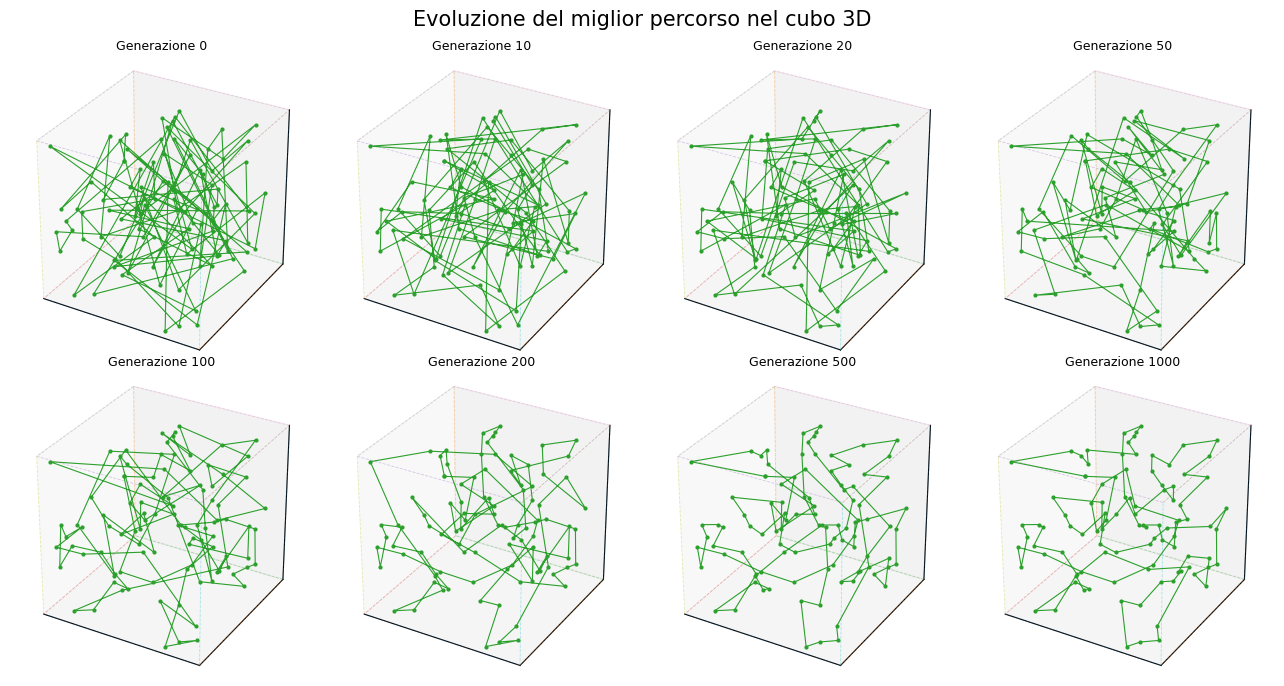

In [66]:
snapshot_generations = [0, 10, 20, 50, 100, 200, 500, 1000]

fig = plt.figure(figsize=(13, 7))


for k, gen in enumerate(snapshot_generations):

    ax = fig.add_subplot(
        2, 4, k + 1,
        projection="3d"
    )


    # Caricamento del miglior percorso della generazione
    data = np.loadtxt(
        f"Esercizio_09_extra_cube/cube_best_path_gen_{gen}.txt"
    )

    points_gen = data[:, 2:5]


    # ========================================================
    # Spigoli del cubo
    # ========================================================

    for i, j in cube_edges:

        ax.plot(
            [cube_vertices[i, 0], cube_vertices[j, 0]],
            [cube_vertices[i, 1], cube_vertices[j, 1]],
            [cube_vertices[i, 2], cube_vertices[j, 2]],
            linestyle="--",
            linewidth=0.6,
            alpha=0.35
        )


    # ========================================================
    # Percorso
    # ========================================================

    ax.plot(
        points_gen[:, 0],
        points_gen[:, 1],
        points_gen[:, 2],
        marker="o",
        markersize=2,
        linewidth=0.8
    )


    ax.set_title(
        f"Generazione {gen}",
        fontsize=9
    )


    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)

    ax.set_box_aspect([1, 1, 1])


    # Rimozione dei tick per rendere
    # la sequenza più leggibile
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])


fig.suptitle(
    "Evoluzione del miglior percorso nel cubo 3D",
    fontsize=15
)

plt.tight_layout()
plt.show()